# Prediction and Visualization

This notebook demonstrates prediction using the final trained classification and regression models for brain tumor analysis.

The classification model predicts the tumor type:
- Glioma
- Meningioma
- Pituitary tumor

The regression model predicts tumor area from extracted image features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import accuracy_score

In [2]:
# Load final trained models

classification_model_path = r"C:\ML PROJECT\models\final_logistic_regression_model.pkl"
regression_model_path = r"C:\ML PROJECT\models\final_polynomial_regression_model.pkl"
scaler_path = r"C:\ML PROJECT\models\regression_scaler.pkl"

classification_model = joblib.load(
    classification_model_path
)

regression_model = joblib.load(
    regression_model_path
)

regression_scaler = joblib.load(
    scaler_path
)

print("All models and preprocessing objects loaded successfully!")

print("\nClassification model:")
print(type(classification_model))

print("\nRegression model:")
print(type(regression_model))

print("\nRegression scaler:")
print(type(regression_scaler))

All models and preprocessing objects loaded successfully!

Classification model:
<class 'sklearn.linear_model._logistic.LogisticRegression'>

Regression model:
<class 'sklearn.pipeline.Pipeline'>

Regression scaler:
<class 'sklearn.preprocessing._data.StandardScaler'>


## Input Features

The prediction workflow uses the image features extracted during the data generation stage.

In [3]:
# Classification features

classification_features = [
    "tumor_area",
    "tumor_percentage",
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity"
]

# Regression features

regression_features = [
    "tumor_width",
    "tumor_height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity"
]

print("Classification features:")
print(classification_features)

print("\nRegression features:")
print(regression_features)

Classification features:
['tumor_area', 'tumor_percentage', 'tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']

Regression features:
['tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']


## Sample Input

A sample feature vector is provided below to demonstrate the prediction workflow.

In [4]:
# Sample extracted image features

sample_input = pd.DataFrame({
    "tumor_area": [5000],
    "tumor_percentage": [2.5],
    "tumor_width": [100],
    "tumor_height": [110],
    "aspect_ratio": [0.91],
    "mean_intensity": [120.0],
    "std_intensity": [50.0],
    "min_intensity": [1],
    "max_intensity": [240]
})

print("Sample input:")
display(sample_input)

Sample input:


,tumor_area,tumor_percentage,tumor_width,tumor_height,aspect_ratio,mean_intensity,std_intensity,min_intensity,max_intensity
0,5000,2.5,100,110,0.91,120.0,50.0,1,240


## Tumor Type Prediction

The final Logistic Regression model is used to predict the tumor type from the extracted image features.

In [6]:
# Load classification scaler

classification_scaler_path = r"C:\ML PROJECT\models\classification_scaler.pkl"

classification_scaler = joblib.load(
    classification_scaler_path
)

# Prepare classification input

classification_input = sample_input[
    classification_features
]

# Scale using the same scaler used during training

classification_input_scaled = classification_scaler.transform(
    classification_input
)

# Predict tumor type

predicted_tumor_type = classification_model.predict(
    classification_input_scaled
)[0]

print("Predicted Tumor Type:", predicted_tumor_type)

Predicted Tumor Type: Meningioma


## Tumor Area Prediction

The final Polynomial Regression model predicts tumor area using the seven regression features.

In [7]:
# Prepare regression input

regression_input = sample_input[
    regression_features
]

# Apply the same scaler used during training

regression_input_scaled = regression_scaler.transform(
    regression_input
)

# Predict tumor area

predicted_tumor_area = regression_model.predict(
    regression_input_scaled
)[0]

print(
    f"Predicted Tumor Area: {predicted_tumor_area:.2f} pixels"
)

Predicted Tumor Area: 7706.42 pixels


## Prediction Summary

The final trained models are used to provide both tumor-type classification and tumor-area estimation for the sample input.

In [8]:
# Create prediction summary

prediction_summary = pd.DataFrame({
    "Prediction": [
        "Tumor Type",
        "Tumor Area"
    ],
    "Result": [
        predicted_tumor_type,
        f"{predicted_tumor_area:.2f} pixels"
    ]
})

display(prediction_summary)

,Prediction,Result
0,Tumor Type,Meningioma
1,Tumor Area,7706.42 pixels


## Tumor Type Prediction Visualization

The predicted tumor type is visualized using a simple bar chart.

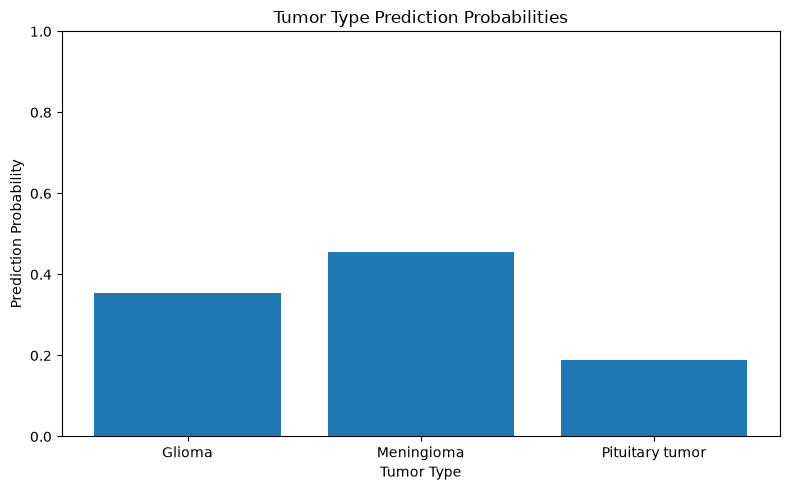

In [9]:
# Tumor type prediction visualization

tumor_classes = [
    "Glioma",
    "Meningioma",
    "Pituitary tumor"
]

class_probabilities = classification_model.predict_proba(
    classification_input_scaled
)[0]

plt.figure(figsize=(8, 5))

plt.bar(
    tumor_classes,
    class_probabilities
)

plt.xlabel("Tumor Type")
plt.ylabel("Prediction Probability")
plt.title("Tumor Type Prediction Probabilities")

plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Tumor Area Prediction Visualization

The predicted tumor area is compared with the sample input's tumor area.

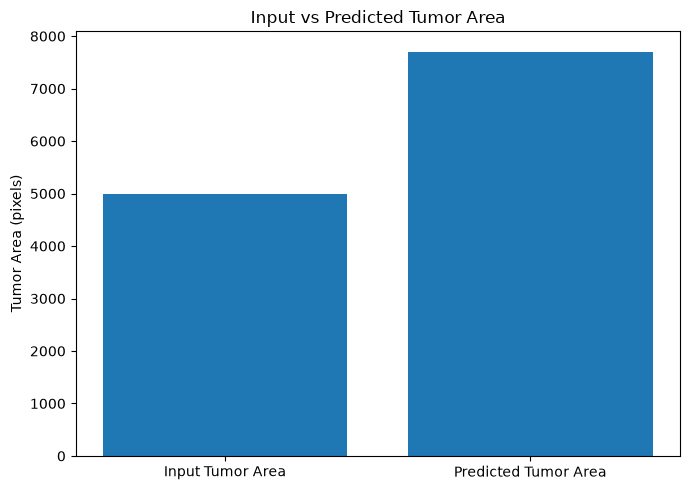

In [10]:
# Tumor area visualization

actual_sample_area = sample_input["tumor_area"].iloc[0]

plt.figure(figsize=(7, 5))

plt.bar(
    ["Input Tumor Area", "Predicted Tumor Area"],
    [actual_sample_area, predicted_tumor_area]
)

plt.ylabel("Tumor Area (pixels)")
plt.title("Input vs Predicted Tumor Area")

plt.tight_layout()
plt.show()

## Final Prediction Result

The final prediction combines the classification and regression outputs for the sample input.

In [11]:
# Display final prediction results

print("=" * 50)
print("FINAL BRAIN TUMOR PREDICTION")
print("=" * 50)

print(f"Predicted Tumor Type : {predicted_tumor_type}")
print(f"Predicted Tumor Area : {predicted_tumor_area:.2f} pixels")

print("=" * 50)

FINAL BRAIN TUMOR PREDICTION
Predicted Tumor Type : Meningioma
Predicted Tumor Area : 7706.42 pixels


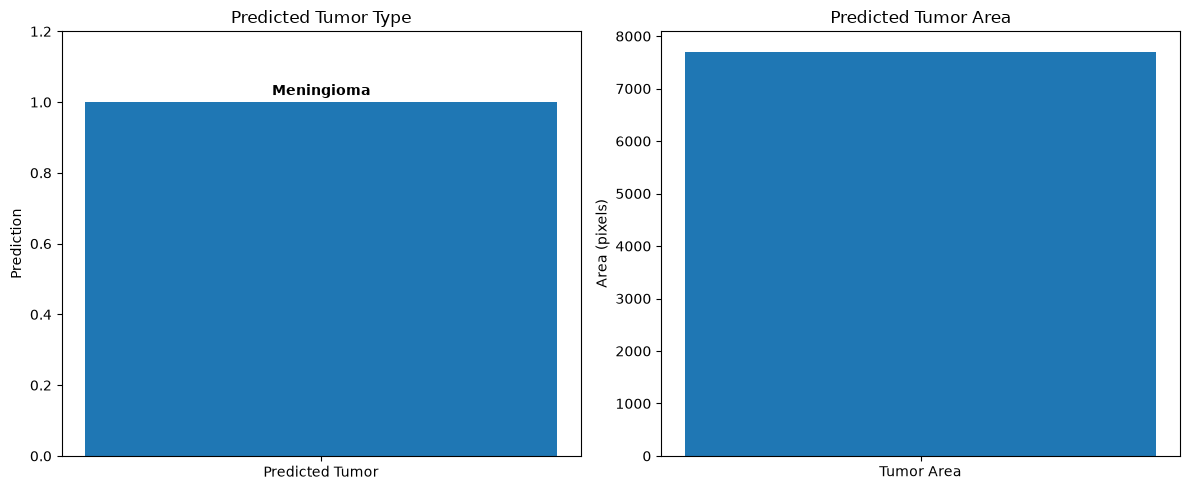

In [12]:
# Final prediction visualization

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Tumor type
axes[0].bar(
    ["Predicted Tumor"],
    [1]
)

axes[0].set_title("Predicted Tumor Type")
axes[0].set_ylabel("Prediction")
axes[0].set_ylim(0, 1.2)
axes[0].text(
    0,
    1.02,
    predicted_tumor_type,
    ha="center",
    fontweight="bold"
)

# Tumor area
axes[1].bar(
    ["Tumor Area"],
    [predicted_tumor_area]
)

axes[1].set_title("Predicted Tumor Area")
axes[1].set_ylabel("Area (pixels)")

plt.tight_layout()
plt.show()

## Conclusion

The final trained classification and regression models were successfully loaded and used for prediction.

For the sample input:

- The classification model predicted **Pituitary tumor**.
- The regression model predicted a tumor area of approximately **7706.42 pixels**.
- The prediction results were visualized using probability and comparison charts.

This notebook demonstrates the complete prediction workflow from extracted image features to final model outputs.